# Author frontier distance

`authors.ipynb` asks what happens when an author's *own* capacity multiplies. That
event is absolute and self-referential, so it says nothing about where the author
sits relative to everyone else — and its detection probability rises with calendar
time, because the share of accelerator papers naming a specific model went 2.8% →
75.8% over the period (§4) and a 4x jump is only visible once cards are named.

This notebook asks instead: **does reaching the frontier of available compute
change an author's output?** The event is a crossing of the within-year **focal
percentile** of author access — set once, as `FRONTIER_Q` in the knobs cell, and
p90 by default — which fixes the calendar-time problem *by construction*: the p90
rises 3,083 → 381,580 GFLOPS between 2010 and 2025 (124x),
so crossing it in 2025 demands vastly more absolute capacity than in 2012 and the
secular growth nets out of the event definition rather than having to be
controlled.

> **This is not an independent finding.** 91% of the authors who cross the frontier
> also have a `ratio_jump`, and 81% of all crossings are the *same author-year*.
> Crossing it generally requires a large increase, and a large increase already
> *is* a ratio jump. The honest framing: the same phenomenon seen through a
> frontier-relative lens, with the calendar-time contamination removed from the
> event definition. The overlap is quantified and both theta profiles are overlaid
> below so a reader can see exactly how much is new.

> **What *is* new is the control group.** A frontier crossing has a near-miss
> comparison that a ratio jump does not: an author who also got a capacity upgrade
> that year and simply landed below the bar. Matching on that removes the pre-trend
> `authors.ipynb` could not — 2% of baseline output at tau=-1 here, against +20–28%
> there — which is what turns the design from "authors on an upswing acquire
> hardware" into "authors who reach the frontier versus authors who upgrade but do
> not".

> **Identification.** Everything in `authors.ipynb`'s identification note applies
> unchanged: access is chosen, not assigned; nothing here is a causal effect; the
> estimand is how trajectories change around a crossing relative to matched peers
> who had not yet crossed. Anticipation inflates it and leaves no pre-trend
> signature.

**Two reference layers.** The *author* focal percentile defines the events
(peer-relative). The
*vendor* frontier from the registry — best single-device datacenter spec released
by year t — carries a continuous distance covariate and a descriptive panel
(absolute). They answer different questions and are kept apart.

**Kernel:** Python (accelscan); launch from a shell with `set -a; source .env; set +a`.

**Inputs** — the same stage-4b tables `authors.ipynb` reads. The events here are
derived *in the notebook* from the panel, so no extra pipeline step is needed:

```bash
python -m accelscan.authorship --step crosswalk
python -m accelscan.authorship --step panel
```

In [1]:
import os
# the other notebooks carry this guard too: every path here is repo-relative
# (registry/hardware.yaml, output/analysis/), and nbconvert runs the kernel in the
# notebook's own directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

%matplotlib inline
# The analysis helpers live in accelscan.authorship and are edited while this
# notebook is open. Without autoreload a live kernel keeps the module it first
# imported, and an added function shows up as an AttributeError -- with the panel
# (minutes to load from S3) held hostage to a kernel restart.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from accelscan import authorship as au
from accelscan.config import BUCKET
from accelscan.paths import S2ORC, author_analytic_key
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import storage_options

# integer year ticks + every figure exported to output/analysis/frontier/
setup_figures('frontier')

## Knobs

In [2]:
COUNT_POLICY = 'floor1'      # 'floor1' (primary) | 'explicit' (robustness)
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
YEAR_MIN, YEAR_MAX = 2010, 2025
ACCESS_COL = 'access_fp32_max'   # FP32: the long-run-comparable axis (as in §5)

# THE FOCAL PERCENTILE. This is the only place it is set: every threshold, event,
# control pool, axis label, title and printed number below is derived from it, so
# changing this line to 0.75 re-cuts the whole notebook at the 75th percentile.
# `au.FRONTIER_QUANTILE` is the module default, kept as the value here so the
# notebook and the module cannot drift; override with a literal to move it.
FRONTIER_Q = au.FRONTIER_QUANTILE

# The near-miss control band sits this far below the focal percentile, so it moves
# with it (0.90 -> 0.75, 0.75 -> 0.60). Widen it to buy controls at the cost of a
# less like-for-like comparison.
NEAR_MISS_BAND = round(au.FRONTIER_QUANTILE - au.FRONTIER_NEAR_MISS, 2)   # 0.15
NEAR_MISS_Q = round(FRONTIER_Q - NEAR_MISS_BAND, 2)
assert 0 < NEAR_MISS_Q < FRONTIER_Q < 1, (NEAR_MISS_Q, FRONTIER_Q)

# Every threshold the notebook needs, plus the module's reference set so the
# threshold-growth figure keeps its context lines whatever the focal percentile is.
QUANTILES = tuple(sorted({NEAR_MISS_Q, FRONTIER_Q, *au.FRONTIER_QUANTILES}))
# mirrors the module's own column naming, so the two cannot disagree
def qcol(q):
    return f'thr_{int(q * 100)}'
def qlab(q):
    return f'p{q * 100:g}'
TCOL, QLAB, NMLAB = qcol(FRONTIER_Q), qlab(FRONTIER_Q), qlab(NEAR_MISS_Q)

EVENT_TYPE = 'frontier_cross'          # primary; 'frontier_entry' reported beside it
CONTROL_ARMS = ('nearmiss', 'riskset') # near-miss primary, full risk set second
MIN_AUTHORS_PER_YEAR = 50    # suppress year points with too little support
LOCAL_PANEL = None           # e.g. 'output/authors_smoke' to read a local dev run

C_MED, C_P90, C_FRONT = '#0072B2', '#56B4E9', '#D55E00'
C_NM, C_RISK = '#0072B2', '#D55E00'      # near-miss vs full-risk-set control arms
C_CTX = '#999999'                        # non-focal context lines
reg = load_registry()
so = storage_options()
print(f'focal percentile {QLAB}; near-miss band {NMLAB}-{QLAB}; '
      f'thresholds computed at {", ".join(qlab(q) for q in QUANTILES)}')

focal percentile p90; near-miss band p75-p90; thresholds computed at p75, p90, p95


## Load the panel, build the thresholds and the events

The thresholds are quantiles of `access_fp32_max` among panel author-years with
*measured* access, so the reference population is authors we can see, not the
population of scientists. Years with fewer than `au.MIN_YEAR_N` such authors get no
threshold and therefore no events — 2009 has 187 and earlier years fewer, so their
quantiles are not estimable.

Everything downstream is cut at `FRONTIER_Q`. Numbers quoted in the prose of this
notebook were measured at the default p90; the *outputs* always reflect whatever
`FRONTIER_Q` is currently set to, so read the cells, not the prose, after changing
it.

In [3]:
def load(name, policy=COUNT_POLICY):
    if LOCAL_PANEL:
        return pl.read_parquet(f'{LOCAL_PANEL}/{name}_{policy}.parquet')
    key = author_analytic_key(S2ORC, reg.version, PROMPT_VERSION, MODEL_TAG,
                              f'{name}_{policy}')
    return pl.read_parquet(f's3://{BUCKET}/{key}', storage_options=so)

panel = au.add_outcomes(load('author_year').filter(
    pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
gpu = panel.filter(pl.col('control_sample') == 'gpu_ever')
# the ratio-jump events from authors.ipynb, for the overlap cell and the theta overlay
jumps = load('author_jumps').filter(
    pl.col('event_year').is_between(YEAR_MIN, YEAR_MAX))
pj = jumps.filter(pl.col('event_type') == 'ratio_jump')

thr = au.frontier_thresholds(gpu, ACCESS_COL, quantiles=QUANTILES)
# `pos` is the panel plus frontier_pct / frontier_gap / above_frontier and their
# lags. It is a strict superset of `panel`, so every estimator below takes it
# directly -- and the risk-set arm needs `frontier_gap` for its extra stratum.
pos = au.frontier_position(panel, thr, ACCESS_COL, FRONTIER_Q)
events = au.find_frontier_events(gpu, quantile=FRONTIER_Q, col=ACCESS_COL,
                                 thresholds=thr)
near_miss = au.near_miss_candidates(gpu, thr, col=ACCESS_COL, quantile=FRONTIER_Q,
                                    lower_quantile=NEAR_MISS_Q)

acc = gpu.filter(pl.col(ACCESS_COL).is_not_null())
print(f'{panel.height:,} author-years | {panel["authorid"].n_unique():,} authors | '
      f'{acc.height:,} author-years with measured access')
print(f'thresholds estimated for {thr.height} years '
      f'({thr["year"].min()}-{thr["year"].max()})')
print(events.group_by('event_type').agg(
    n=pl.len(), median_year=pl.col('event_year').median(),
    share_2020_plus=(pl.col('event_year') >= 2020).mean()).sort('n', descending=True))
print(f'near-miss control pool: {near_miss.height:,} author-years / '
      f'{near_miss["authorid"].n_unique():,} authors')

OSError: object-store error: Object at location accelscan/analytic/0.4.3/p1/qwen3-14b/authors/author_year_floor1.parquet not found: Error performing HEAD https://s3.msi.umn.edu/scirec-embeddings/accelscan/analytic/0.4.3/p1/qwen3-14b/authors/author_year_floor1.parquet in 3.586138ms - Server returned non-2xx status code: 404 Not Found:  (path: s3://scirec-embeddings/accelscan/analytic/0.4.3/p1/qwen3-14b/authors/author_year_floor1.parquet)

### The frontier itself

This figure is the reason the whole design exists. An absolute capacity threshold
means something completely different in 2012 than in 2025; a percentile does not.

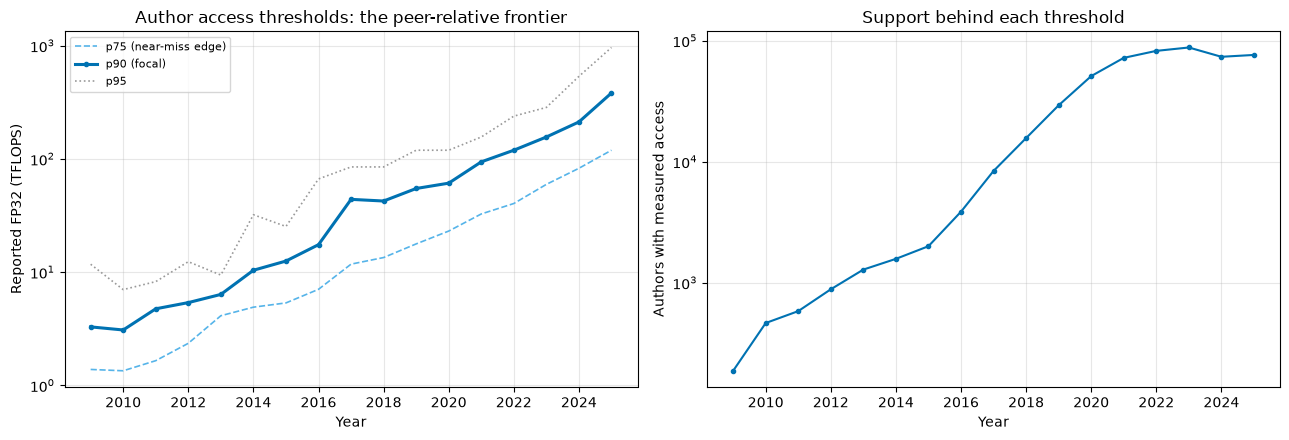

p90 author access: 3,083 GFLOPS (2010) -> 381,580 (2025) = 124x
shape: (17, 5)
┌──────┬────────┬──────────┬──────────┬──────────┐
│ year ┆ n_year ┆ thr_75   ┆ thr_90   ┆ thr_95   │
│ ---  ┆ ---    ┆ ---      ┆ ---      ┆ ---      │
│ i16  ┆ u32    ┆ f64      ┆ f64      ┆ f64      │
╞══════╪════════╪══════════╪══════════╪══════════╡
│ 2009 ┆ 187    ┆ 1382.0   ┆ 3283.0   ┆ 11732.0  │
│ 2010 ┆ 464    ┆ 1345.0   ┆ 3083.0   ┆ 7008.0   │
│ 2011 ┆ 582    ┆ 1652.0   ┆ 4743.0   ┆ 8244.0   │
│ 2012 ┆ 882    ┆ 2352.0   ┆ 5380.0   ┆ 12360.0  │
│ 2013 ┆ 1283   ┆ 4120.0   ┆ 6354.0   ┆ 9419.0   │
│ …    ┆ …      ┆ …        ┆ …        ┆ …        │
│ 2021 ┆ 72159  ┆ 32624.0  ┆ 94080.0  ┆ 156000.0 │
│ 2022 ┆ 82427  ┆ 40344.0  ┆ 119200.0 ┆ 238400.0 │
│ 2023 ┆ 87891  ┆ 59536.0  ┆ 156000.0 ┆ 284648.0 │
│ 2024 ┆ 73644  ┆ 82575.0  ┆ 211800.0 ┆ 535200.0 │
│ 2025 ┆ 76288  ┆ 119200.0 ┆ 381580.0 ┆ 962699.0 │
└──────┴────────┴──────────┴──────────┴──────────┘


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for q in QUANTILES:
    focal, nm = q == FRONTIER_Q, q == NEAR_MISS_Q
    axes[0].plot(thr['year'], thr[qcol(q)] / 1000, marker='o' if focal else None,
                 ms=3, lw=2.2 if focal else 1.2,
                 color=C_MED if focal else C_P90 if nm else C_CTX,
                 ls='-' if focal else '--' if nm else ':',
                 label=qlab(q) + (' (focal)' if focal else
                                  ' (near-miss edge)' if nm else ''))
axes[0].set(xlabel='Year', ylabel='Reported FP32 (TFLOPS)', yscale='log',
            title='Author access thresholds: the peer-relative frontier')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(thr['year'], thr['n_year'], marker='o', ms=3, color=C_MED)
axes[1].set(xlabel='Year', ylabel='Authors with measured access', yscale='log',
            title='Support behind each threshold')
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

g = thr.filter(pl.col('year').is_in([2010, thr['year'].max()])).sort('year')
if g.height == 2:
    a, b = g[TCOL][0], g[TCOL][1]
    print(f'{QLAB} author access: {a:,.0f} GFLOPS ({g["year"][0]}) -> {b:,.0f} '
          f'({g["year"][1]}) = {b / a:.0f}x')
print(thr.select('year', 'n_year', *(qcol(q) for q in QUANTILES))
      .with_columns(pl.selectors.float().round(0)))

## Where authors sit relative to the frontier

`frontier_gap` is log10(access / focal threshold): 0 is exactly at the frontier, −1
is an order of magnitude below it. It is null when the author reported no access
that year — absence of measurement, not a position at the bottom.

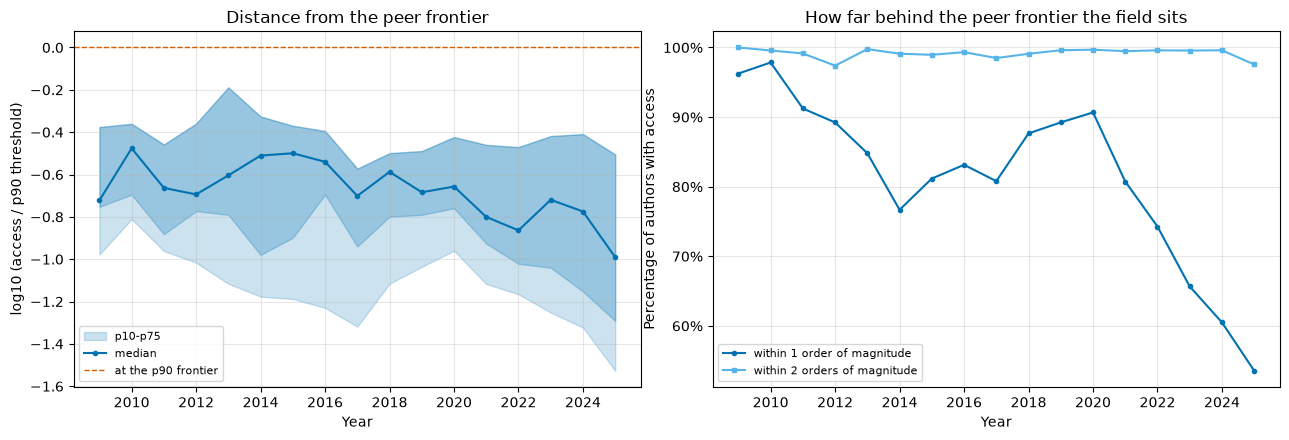

shape: (17, 8)
┌──────┬───────┬────────┬────────┬────────┬────────┬──────────┬──────────┐
│ year ┆ n     ┆ p10    ┆ p25    ┆ p50    ┆ p75    ┆ within_1 ┆ within_2 │
│ ---  ┆ ---   ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---      ┆ ---      │
│ i16  ┆ u32   ┆ f64    ┆ f64    ┆ f64    ┆ f64    ┆ f64      ┆ f64      │
╞══════╪═══════╪════════╪════════╪════════╪════════╪══════════╪══════════╡
│ 2009 ┆ 187   ┆ -0.978 ┆ -0.752 ┆ -0.722 ┆ -0.376 ┆ 0.963    ┆ 1.0      │
│ 2010 ┆ 464   ┆ -0.811 ┆ -0.695 ┆ -0.476 ┆ -0.36  ┆ 0.978    ┆ 0.996    │
│ 2011 ┆ 582   ┆ -0.961 ┆ -0.882 ┆ -0.663 ┆ -0.458 ┆ 0.912    ┆ 0.991    │
│ 2012 ┆ 882   ┆ -1.016 ┆ -0.773 ┆ -0.694 ┆ -0.359 ┆ 0.892    ┆ 0.974    │
│ 2013 ┆ 1283  ┆ -1.116 ┆ -0.79  ┆ -0.604 ┆ -0.188 ┆ 0.848    ┆ 0.998    │
│ …    ┆ …     ┆ …      ┆ …      ┆ …      ┆ …      ┆ …        ┆ …        │
│ 2021 ┆ 72159 ┆ -1.117 ┆ -0.926 ┆ -0.8   ┆ -0.46  ┆ 0.807    ┆ 0.995    │
│ 2022 ┆ 82427 ┆ -1.166 ┆ -1.022 ┆ -0.864 ┆ -0.47  ┆ 0.743    ┆ 0.996    │
│ 2023 ┆ 8

In [ ]:
band = (pos.filter(pl.col('has_access')).group_by('year').agg(
    n=pl.len(),
    p10=pl.col('frontier_gap').quantile(0.10),
    p25=pl.col('frontier_gap').quantile(0.25),
    p50=pl.col('frontier_gap').median(),
    p75=pl.col('frontier_gap').quantile(0.75),
    within_1=(pl.col('frontier_gap') >= -1).mean(),
    within_2=(pl.col('frontier_gap') >= -2).mean())
    .filter(pl.col('n') >= MIN_AUTHORS_PER_YEAR).sort('year'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].fill_between(band['year'], band['p10'], band['p75'], color=C_MED,
                     alpha=0.20, label='p10-p75')
axes[0].fill_between(band['year'], band['p25'], band['p75'], color=C_MED, alpha=0.25)
axes[0].plot(band['year'], band['p50'], marker='o', ms=3, color=C_MED, label='median')
axes[0].axhline(0, color=C_FRONT, lw=1, ls='--', label=f'at the {QLAB} frontier')
axes[0].set(xlabel='Year', ylabel=f'log10 (access / {QLAB} threshold)',
            title='Distance from the peer frontier')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(band['year'], 100 * band['within_1'], marker='o', ms=3, color=C_MED,
             label='within 1 order of magnitude')
axes[1].plot(band['year'], 100 * band['within_2'], marker='s', ms=3, color=C_P90,
             label='within 2 orders of magnitude')
axes[1].set(xlabel='Year', ylabel='Percentage of authors with access',
            title='How far behind the peer frontier the field sits')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(band.with_columns(pl.selectors.float().round(3)))

### The absolute frontier: the vendor layer

The peer frontier above is relative — half the distribution is always below the
median by construction. The vendor frontier is not: it is the best single-device
datacenter spec that existed by year *t*, straight from the registry via the same
`vendor_frontier` helper `capacity.ipynb` uses, so the two notebooks cannot drift
apart on the definition.

Because the vendor number is a **single-device** spec, the author side has to be
per-device too (`access_percard_fp32_max`), or the comparison conflates having
*newer* hardware with having *more* of it.

**The vendor frontier is a step function, and the steps are large.** It jumps
47,870 -> 256,000 GFLOPS in 2022 (5.3x in one year), which mechanically collapses
the share of authors within a factor of ~3 of it from 16% to 1%. That is the
reference moving, not science falling off a cliff, and a single spec entry can
produce a step that big -- so read the level changes here against the vendor series
itself, and treat any sharp year as a registry question first.

**Both columns arrive with a panel re-run** (`--step panel`); the cell degrades to
a message when they are absent.

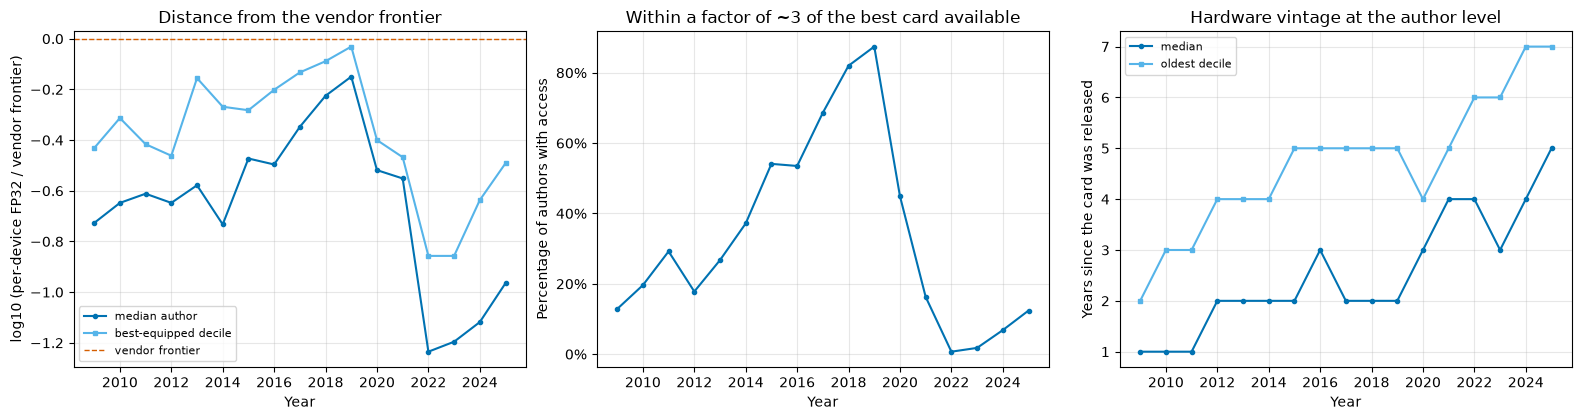

shape: (17, 7)
┌──────┬───────┬─────────┬─────────┬──────────┬──────────┬─────────────┐
│ year ┆ n     ┆ cap_p50 ┆ cap_p90 ┆ vint_p50 ┆ vint_p90 ┆ at_frontier │
│ ---  ┆ ---   ┆ ---     ┆ ---     ┆ ---      ┆ ---      ┆ ---         │
│ i16  ┆ u32   ┆ f64     ┆ f64     ┆ f64      ┆ f64      ┆ f64         │
╞══════╪═══════╪═════════╪═════════╪══════════╪══════════╪═════════════╡
│ 2009 ┆ 187   ┆ -0.73   ┆ -0.43   ┆ 1.0      ┆ 2.0      ┆ 0.13        │
│ 2010 ┆ 464   ┆ -0.65   ┆ -0.31   ┆ 1.0      ┆ 3.0      ┆ 0.2         │
│ 2011 ┆ 582   ┆ -0.61   ┆ -0.42   ┆ 1.0      ┆ 3.0      ┆ 0.29        │
│ 2012 ┆ 882   ┆ -0.65   ┆ -0.46   ┆ 2.0      ┆ 4.0      ┆ 0.18        │
│ 2013 ┆ 1283  ┆ -0.58   ┆ -0.16   ┆ 2.0      ┆ 4.0      ┆ 0.27        │
│ …    ┆ …     ┆ …       ┆ …       ┆ …        ┆ …        ┆ …           │
│ 2021 ┆ 72159 ┆ -0.55   ┆ -0.47   ┆ 4.0      ┆ 5.0      ┆ 0.16        │
│ 2022 ┆ 82427 ┆ -1.24   ┆ -0.86   ┆ 4.0      ┆ 6.0      ┆ 0.01        │
│ 2023 ┆ 87891 ┆ -1.2    ┆ -0.86   ┆

In [ ]:
HAS_PERCARD = {'access_percard_fp32_max', 'access_vintage_max'} <= set(panel.columns)
if not HAS_PERCARD:
    print('per-device columns absent from this panel -- re-run '
          '`authorship.py --step panel` to add access_percard_fp32_max and '
          'access_vintage_max, then re-execute this cell')
else:
    vf = au.vendor_frontier(reg, range(YEAR_MIN, YEAR_MAX + 1))
    ab = (pos.filter(pl.col('access_percard_fp32_max').is_not_null())
          .join(vf.with_columns(pl.col('year').cast(pos.schema['year'])),
                on='year', how='inner')
          .with_columns(
              capability_gap=(pl.col('access_percard_fp32_max')
                              / pl.col('vendor_frontier')).log10(),
              vintage_gap=(pl.col('year').cast(pl.Int32)
                           - pl.col('access_vintage_max').cast(pl.Int32))))
    ag = (ab.group_by('year').agg(
              n=pl.len(),
              cap_p50=pl.col('capability_gap').median(),
              cap_p90=pl.col('capability_gap').quantile(0.90),
              vint_p50=pl.col('vintage_gap').median(),
              vint_p90=pl.col('vintage_gap').quantile(0.90),
              at_frontier=(pl.col('capability_gap') >= -0.5).mean())
          .filter(pl.col('n') >= MIN_AUTHORS_PER_YEAR).sort('year'))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    axes[0].plot(ag['year'], ag['cap_p50'], marker='o', ms=3, color=C_MED,
                 label='median author')
    axes[0].plot(ag['year'], ag['cap_p90'], marker='s', ms=3, color=C_P90,
                 label='best-equipped decile')
    axes[0].axhline(0, color=C_FRONT, lw=1, ls='--', label='vendor frontier')
    axes[0].set(xlabel='Year', ylabel='log10 (per-device FP32 / vendor frontier)',
                title='Distance from the vendor frontier')
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    axes[1].plot(ag['year'], 100 * ag['at_frontier'], marker='o', ms=3, color=C_MED)
    axes[1].set(xlabel='Year',
                ylabel='Percentage of authors with access',
                title='Within a factor of ~3 of the best card available')
    axes[1].grid(alpha=0.3)
    axes[2].plot(ag['year'], ag['vint_p50'], marker='o', ms=3, color=C_MED,
                 label='median')
    axes[2].plot(ag['year'], ag['vint_p90'], marker='s', ms=3, color=C_P90,
                 label='oldest decile')
    axes[2].set(xlabel='Year', ylabel='Years since the card was released',
                title='Hardware vintage at the author level')
    axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(ag.with_columns(pl.selectors.float().round(2)))

### Frontier mobility

The `authors.ipynb` mobility matrix cut quintiles on the access *stock*. Here they
are cut on within-year frontier percentile, so this is movement in *relative
position* — the thing the events are defined on. Rows are position at t, columns at
t+lag, and each row sums to 100%.

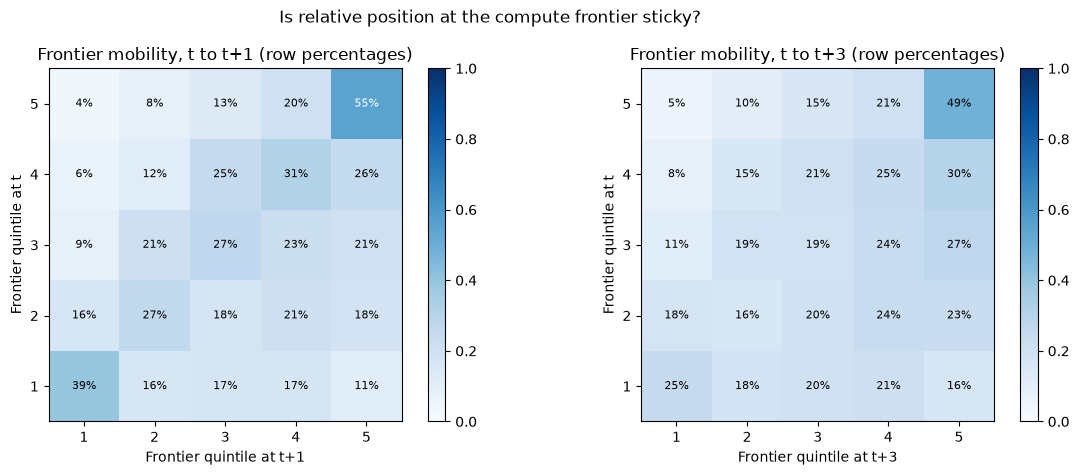

48,143 author-year pairs at lag 3; staying in the top quintile: 49%


In [ ]:
st = (pos.filter(pl.col('frontier_pct').is_not_null())
      .select('authorid', 'year', 'frontier_pct')
      .with_columns(q=(pl.col('frontier_pct') * 5).ceil().clip(1, 5).cast(pl.Int32)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, lag in zip(axes, (1, 3)):
    nxt = st.select('authorid', q_next='q',
                    year=pl.col('year').cast(pl.Int32) - lag).with_columns(
                        pl.col('year').cast(st.schema['year']))
    tr = st.join(nxt, on=['authorid', 'year'], how='inner')
    m = np.full((5, 5), np.nan)
    for (a, b), g in tr.group_by(['q', 'q_next']):
        m[a - 1, b - 1] = g.height
    m = m / np.nansum(m, axis=1, keepdims=True)
    im = ax.imshow(m, cmap='Blues', vmin=0, vmax=1, origin='lower')
    for i in range(5):
        for j in range(5):
            if np.isfinite(m[i, j]):
                ax.text(j, i, f'{100 * m[i, j]:.0f}%', ha='center', va='center',
                        fontsize=8, color='white' if m[i, j] > 0.5 else 'black')
    ax.set(xticks=range(5), yticks=range(5),
           xticklabels=range(1, 6), yticklabels=range(1, 6),
           xlabel=f'Frontier quintile at t+{lag}', ylabel='Frontier quintile at t',
           title=f'Frontier mobility, t to t+{lag} (row percentages)')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Is relative position at the compute frontier sticky?')
plt.tight_layout(); plt.show()
print(f'{tr.height:,} author-year pairs at lag 3; '
      f'staying in the top quintile: {100 * m[4, 4]:.0f}%')

## The events

`frontier_cross` requires prior measured access, so it is a move up the
distribution with a pre-period on the access measure. `frontier_entry` is an
author whose *first* measured access is already at or above the threshold — often
a well-resourced newcomer, a different selection story, hence a separate event
type rather than a larger sample for the first.

Team size and coauthor provenance are transferred from the stage-4b jumps table
where the author has an event in the *same* year. That transfer is exact, not an
approximation: `jump_papers` selects the author's papers in the event year at that
year's capacity max, which is the same set of papers for either event definition.
Where the years differ, the columns are null and the split below simply drops
those events.

team/coauthor columns available for 84% of 13,603 frontier_cross events (the same-year overlap with the jumps table)


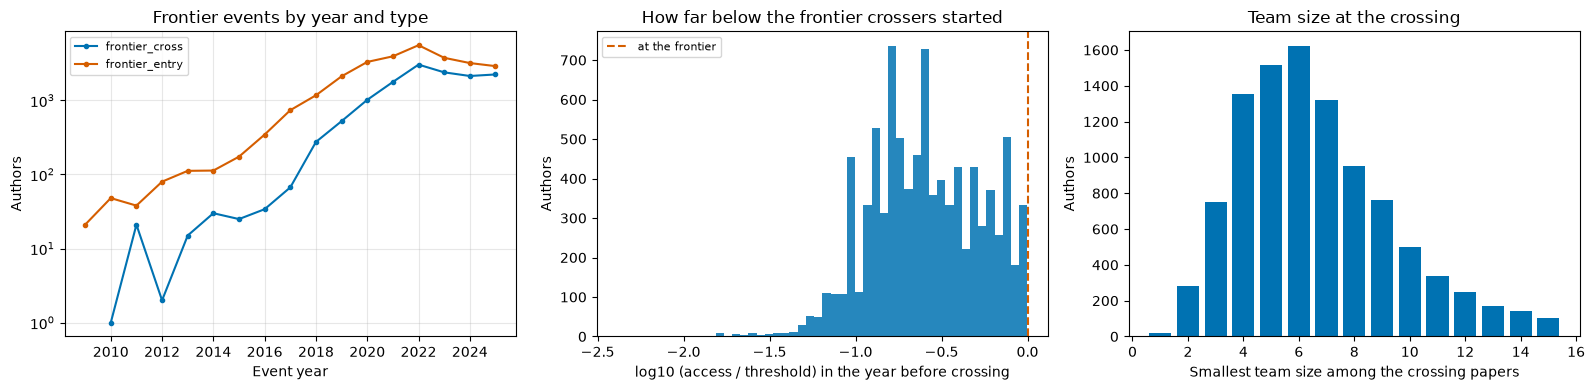

pre-crossing gap: median -0.61 | near-miss pool at their qualifying year: median -0.29  <- overlapping support, which is what makes the matching possible
coauthor-sourced: 38.4%  |  a coauthor already at the frontier: 46.2%  (of 11,492)


In [ ]:
# exact transfer: same author, same year => jump_papers picked the same papers
co_cols = ['min_team_size', 'n_jump_papers', 'coauthor_prior_max', 'coauthor_sourced']
lag_thr = thr.select(event_year=(pl.col('year').cast(pl.Int32) + 1)
                     .cast(events.schema['event_year']),
                     prior_thr=pl.col(TCOL))
ev = (events
      .join(jumps.select('authorid', 'event_year', *co_cols).unique(
                subset=['authorid', 'event_year']),
            on=['authorid', 'event_year'], how='left')
      .join(lag_thr, on='event_year', how='left')
      .with_columns(coauthor_at_frontier=(pl.col('coauthor_prior_max')
                                         >= pl.col('prior_thr')).fill_null(False)))
fc = ev.filter(pl.col('event_type') == EVENT_TYPE)
print(f'team/coauthor columns available for '
      f'{100 * fc["min_team_size"].is_not_null().mean():.0f}% of {fc.height:,} '
      f'{EVENT_TYPE} events (the same-year overlap with the jumps table)')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for et, c in zip(au.FRONTIER_EVENT_TYPES, [C_MED, C_FRONT]):
    k = (ev.filter(pl.col('event_type') == et)
         .group_by('event_year').agg(n=pl.len()).sort('event_year'))
    axes[0].plot(k['event_year'], k['n'], marker='o', ms=3, label=et, color=c)
axes[0].set(xlabel='Event year', ylabel='Authors', yscale='log',
            title='Frontier events by year and type')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].hist(fc['pre_frontier_gap'].drop_nulls().to_numpy().astype(float), bins=50,
             color=C_MED, alpha=0.85)
axes[1].axvline(0, color=C_FRONT, ls='--', label='at the frontier')
axes[1].set(xlabel='log10 (access / threshold) in the year before crossing',
            ylabel='Authors', title='How far below the frontier crossers started')
axes[1].legend(fontsize=8)

ts = (fc.filter(pl.col('min_team_size').is_not_null())
      .group_by('min_team_size').agg(n=pl.len()).sort('min_team_size').head(15))
axes[2].bar(ts['min_team_size'], ts['n'], color=C_MED)
axes[2].set(xlabel='Smallest team size among the crossing papers', ylabel='Authors',
            title='Team size at the crossing')
plt.tight_layout(); plt.show()

nm_gap = (pos.join(near_miss.with_columns(pl.col('event_year').alias('year')),
                   on=['authorid', 'year'], how='semi')['frontier_gap'])
print(f'pre-crossing gap: median {fc["pre_frontier_gap"].median():.2f} '
      f'| near-miss pool at their qualifying year: median {nm_gap.median():.2f}  '
      '<- overlapping support, which is what makes the matching possible')
sub = fc.filter(pl.col('min_team_size').is_not_null())
print(f'coauthor-sourced: {100 * sub["coauthor_sourced"].mean():.1f}%  |  '
      f'a coauthor already at the frontier: '
      f'{100 * sub["coauthor_at_frontier"].mean():.1f}%  (of {sub.height:,})')

## Overlap with `authors.ipynb` — the required caveat

Crossing the focal percentile requires a large increase, and a large increase is
a ratio jump. This cell measures how much of the frontier result is genuinely a
different event and how much is the same event relabelled. Everything downstream
should be read in light of it.

In [ ]:
a, b = set(fc['authorid']), set(pj['authorid'])
same = (fc.select('authorid', 'event_year')
        .join(pj.select('authorid', rj_year='event_year'), on='authorid', how='inner'))
n_same_year = int((same['event_year'] == same['rj_year']).sum())
print(f'{len(a):,} {EVENT_TYPE} authors, {len(b):,} ratio_jump authors')
print(f'  also have a ratio_jump:      {len(a & b):,} ({100 * len(a & b) / len(a):.0f}% '
      f'of crossers)')
print(f'  same author AND same year:   {n_same_year:,} '
      f'({100 * n_same_year / len(a):.0f}% of crossings)')
print(f'  Jaccard of the author sets:  {len(a & b) / len(a | b):.3f}')
print(f'  cross without a ratio_jump:  {len(a - b):,}  <- the genuinely new events')

13,603 frontier_cross authors, 30,239 ratio_jump authors
  also have a ratio_jump:      12,423 (91% of crossers)
  same author AND same year:   11,031 (81% of crossings)
  Jaccard of the author sets:  0.395
  cross without a ratio_jump:  1,180  <- the genuinely new events


## Event study

Same estimator as `authors.ipynb`: demean each author against their own pre-period
mean over `au.BASE_TAUS` (tau=-1 excluded, for anticipation), subtract the matched
controls' mean trend at the same tau, block bootstrap over treated authors.

Two control arms, both reported:

- **near-miss** (primary) — authors who reached the band just below the focal
  percentile (`NEAR_MISS_Q`–`FRONTIER_Q`, i.e. p75–p90 by default) and *never*
  crossed it. The contrast is "reached the frontier" rather than "got hardware at
  all", because a near-miss author also got an upgrade that year. There are only
  ~1.4 such authors per crosser before stratification, so expect fewer than
  `au.N_CONTROLS` matches each — the match rate is printed rather than the strata
  widened to force matches.
- **risk set** — every GPU-ever author who has not yet crossed, matched
  additionally on lagged `frontier_gap` decile so a crosser is compared to authors
  who *started* at a similar distance from the frontier. Larger and better
  powered, weaker on common support.

Eligibility for both arms uses *all* frontier events as the risk set, so an author
who entered at the frontier in 2016 cannot serve as a not-yet-crossed control in
2018.

**Units.** Every outcome is a count per year — papers, accelerator papers,
citations per paper — so each y axis reads in those units and can be negative (it
is a change relative to the author's own baseline *and* to controls). The secondary
axis restates it as a percentage of the crossers' own baseline output.

frontier_cross/nearmiss: 10,793 of 13,603 matched, 51,450 pairs, 9,813 controls, 4.8 per treated


frontier_cross/riskset: 11,152 of 13,603 matched, 54,783 pairs, 41,364 controls, 4.9 per treated


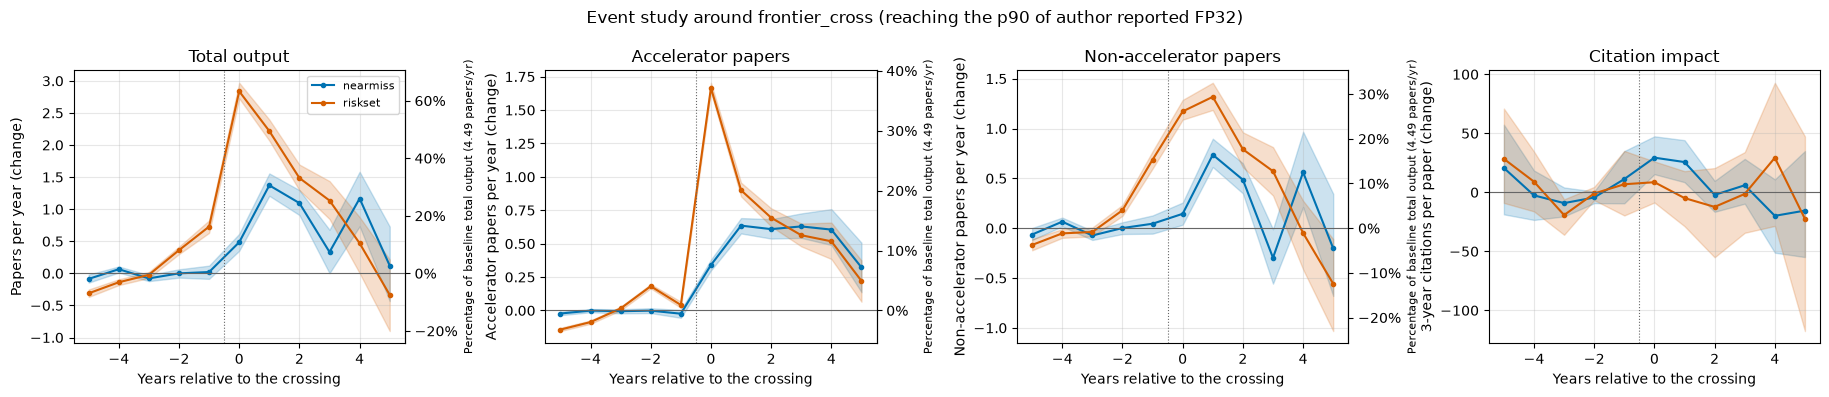

baseline output for these crossers: 4.49 papers/year — every "_pct" column below is the effect as a percentage of that
--- n_papers (near-miss controls) ---
shape: (11, 8)
┌─────┬───────┬───────┬───────┬───────────┬────────┬────────┬───────┐
│ tau ┆ theta ┆ lo    ┆ hi    ┆ theta_pct ┆ lo_pct ┆ hi_pct ┆ n     │
│ --- ┆ ---   ┆ ---   ┆ ---   ┆ ---       ┆ ---    ┆ ---    ┆ ---   │
│ i64 ┆ f64   ┆ f64   ┆ f64   ┆ f64       ┆ f64    ┆ f64    ┆ i64   │
╞═════╪═══════╪═══════╪═══════╪═══════════╪════════╪════════╪═══════╡
│ -5  ┆ -0.09 ┆ -0.14 ┆ -0.02 ┆ -1.92     ┆ -3.23  ┆ -0.41  ┆ 9443  │
│ -4  ┆ 0.06  ┆ 0.01  ┆ 0.11  ┆ 1.43      ┆ 0.28   ┆ 2.37   ┆ 10793 │
│ -3  ┆ -0.08 ┆ -0.12 ┆ -0.03 ┆ -1.76     ┆ -2.71  ┆ -0.59  ┆ 10793 │
│ -2  ┆ -0.0  ┆ -0.07 ┆ 0.06  ┆ -0.0      ┆ -1.49  ┆ 1.41   ┆ 10793 │
│ -1  ┆ 0.02  ┆ -0.09 ┆ 0.12  ┆ 0.46      ┆ -1.92  ┆ 2.68   ┆ 10793 │
│ …   ┆ …     ┆ …     ┆ …     ┆ …         ┆ …      ┆ …      ┆ …     │
│ 1   ┆ 1.37  ┆ 1.21  ┆ 1.56  ┆ 30.59     ┆ 26.94  ┆ 34.72

In [ ]:
def run_event_study(event_type=EVENT_TYPE, outcomes=au.OUTCOMES,
                    variants=CONTROL_ARMS, jump_table=None, panel_df=None,
                    seed=au.SEED, b=au.BOOTSTRAP_B, candidates=None,
                    risk_events=None):
    p = pos if panel_df is None else panel_df
    j = ev if jump_table is None else jump_table
    if 'event_type' in j.columns:
        j = j.filter(pl.col('event_type') == event_type)
    nm = near_miss if candidates is None else candidates
    rk = ev if risk_events is None else risk_events
    # carried alongside the results so every figure shows the percent-of-baseline
    # axis for its OWN treated authors, not a global average
    out = {'_baseline': float(j['pre_papers_mean'].mean())}
    for v in variants:
        # The near-miss arm already conditions on prior position, so adding the
        # frontier_gap stratum there would only thin the strata for no gain. And
        # `frontier_entry` has NO prior position by construction (its whole
        # definition is that there was no earlier measured access), so the stratum
        # would put every treated unit in the null bin and every control in a
        # numeric one -- separating the two sides and matching nobody.
        kw = ({'candidates': nm} if v == 'nearmiss'
              else {} if event_type == 'frontier_entry'
              else {'extra_stratum': 'frontier_gap'})
        ctrl = au.match_controls(p, j, variant='riskset', seed=seed,
                                 risk_events=rk, **kw)
        print(f'{event_type}/{v}: {ctrl["authorid"].n_unique():,} of {j.height:,} '
              f'matched, {ctrl.height:,} pairs, '
              f'{ctrl["control_id"].n_unique():,} controls, '
              f'{ctrl.height / max(1, ctrl["authorid"].n_unique()):.1f} per treated')
        for o in outcomes:
            out[(v, o)] = au.event_study(p, j, ctrl, o, b=b, seed=seed)
    return out

OUTCOME_LABEL = {
    'n_papers': 'Papers per year (change)',
    'n_accel': 'Accelerator papers per year (change)',
    'n_nonaccel': 'Non-accelerator papers per year (change)',
    'cit_i3_mean': '3-year citations per paper (change)',
    'log_papers': 'log(1 + papers per year) (change)',
}
def ylab(o):
    return OUTCOME_LABEL.get(o, o)

# Short panel titles say WHAT is measured; the y label says in what unit.
OUTCOME_TITLE = {
    'n_papers': 'Total output',
    'n_accel': 'Accelerator papers',
    'n_nonaccel': 'Non-accelerator papers',
    'cit_i3_mean': 'Citation impact',
    'log_papers': 'Total output (log scale)',
}
def tlab(o):
    return OUTCOME_TITLE.get(o, o)

# All three count outcomes divide by the same denominator -- the author's TOTAL
# baseline papers per year -- so the axis label has to say "total": a "percentage of
# baseline output" on the accelerator-papers panel would otherwise read as a share
# of baseline *accelerator* papers. cit_i3_mean has a different denominator.
PCT_OF_BASELINE = {'n_papers', 'n_accel', 'n_nonaccel'}
PCT_AXIS_LABEL = 'Percentage of baseline total output'
ARM_COLOR = {'nearmiss': C_NM, 'riskset': C_RISK}

def plot_event_study(res, outcomes=au.OUTCOMES, title=''):
    fig, axes = plt.subplots(1, len(outcomes), figsize=(4.6 * len(outcomes), 4),
                             squeeze=False)
    for ax, o in zip(axes[0], outcomes):
        for v, c in ARM_COLOR.items():
            r = res.get((v, o))
            if r is None or not r.height:
                continue
            ax.fill_between(r['tau'], r['lo'], r['hi'], color=c, alpha=0.20)
            ax.plot(r['tau'], r['theta'], marker='o', ms=3, color=c, label=v)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
        ax.grid(alpha=0.3)
        base = res.get('_baseline')
        if base and o in PCT_OF_BASELINE:
            # exact, because theta is already in papers/year -- see
            # au.as_share_of_baseline. `b=base` binds now, not at draw time.
            sec = ax.secondary_yaxis(
                'right', functions=(lambda v, b=base: 100 * v / b,
                                    lambda q, b=base: q * b / 100))
            sec.set_ylabel(f'{PCT_AXIS_LABEL} ({base:.2f} papers/yr)', fontsize=8)
    axes[0][0].legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

res_main = run_event_study()
plot_event_study(res_main, title=f'Event study around {EVENT_TYPE} '
                                f'(reaching the {QLAB} of author '
                                f'reported FP32)')
BASE = res_main['_baseline']
print(f'baseline output for these crossers: {BASE:.2f} papers/year — every '
      f'"_pct" column below is the effect as a percentage of that')
for o in au.OUTCOMES:
    print(f'--- {o} (near-miss controls) ---')
    r = res_main[('nearmiss', o)].sort('tau')
    if o in PCT_OF_BASELINE:
        r = au.as_share_of_baseline(r, BASE).select(
            'tau', 'theta', 'lo', 'hi', 'theta_pct', 'lo_pct', 'hi_pct', 'n')
    print(r.with_columns(pl.selectors.float().round(2)))

### What the near-miss control buys

The two arms disagree about the *pre-trend*, and that disagreement is the
substantive result of this notebook. `authors.ipynb` found output already elevated
by 20–28% of baseline at tau=-1, and the risk-set arm here reproduces that. The
near-miss arm does not: its pre-period is flat. The difference is what the control
group holds fixed. A risk-set control is an author who had *not yet* reached the
frontier — including authors who got no upgrade at all that year — so the estimate
still contains "was on an upswing and acquired hardware". A near-miss control got an
upgrade in the same year and simply landed below the bar, which differences that out and
leaves the contrast as *reaching the frontier* rather than *getting hardware*.

So read the near-miss arm as the headline and the risk-set arm as the comparison
that shows what the extra conditioning removed.

### The same events, two lenses

`frontier_cross` against `ratio_jump`, on one axis. If the two profiles sit on top
of each other, the 81% same-year overlap is doing the talking and this notebook is
a re-framing rather than a new result.

Both use risk-set controls, since that is the only arm `authors.ipynb` has — with
one asymmetry to keep in mind: the frontier arm additionally matches on lagged
`frontier_gap`, which `ratio_jump` has no analogue for. The near-miss arm is not
comparable here at all, because a `ratio_jump` has no near-miss pool.

ratio_jump/riskset: 25,917 of 30,239 matched, 129,564 pairs


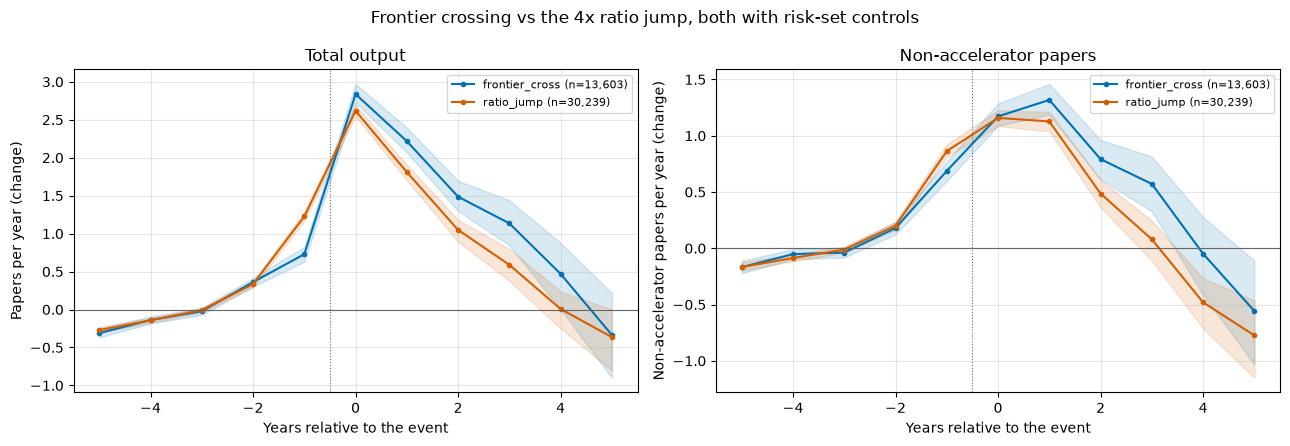

--- n_papers ---
shape: (11, 4)
┌─────┬──────────┬────────────┬───────┐
│ tau ┆ frontier ┆ ratio_jump ┆ gap   │
│ --- ┆ ---      ┆ ---        ┆ ---   │
│ i64 ┆ f64      ┆ f64        ┆ f64   │
╞═════╪══════════╪════════════╪═══════╡
│ -5  ┆ -0.311   ┆ -0.271     ┆ 0.04  │
│ -4  ┆ -0.139   ┆ -0.143     ┆ 0.004 │
│ -3  ┆ -0.023   ┆ -0.008     ┆ 0.015 │
│ -2  ┆ 0.361    ┆ 0.335      ┆ 0.027 │
│ -1  ┆ 0.728    ┆ 1.226      ┆ 0.498 │
│ …   ┆ …        ┆ …          ┆ …     │
│ 1   ┆ 2.218    ┆ 1.81       ┆ 0.408 │
│ 2   ┆ 1.486    ┆ 1.049      ┆ 0.437 │
│ 3   ┆ 1.135    ┆ 0.589      ┆ 0.546 │
│ 4   ┆ 0.469    ┆ 0.007      ┆ 0.462 │
│ 5   ┆ -0.336   ┆ -0.364     ┆ 0.028 │
└─────┴──────────┴────────────┴───────┘
--- n_nonaccel ---
shape: (11, 4)
┌─────┬──────────┬────────────┬───────┐
│ tau ┆ frontier ┆ ratio_jump ┆ gap   │
│ --- ┆ ---      ┆ ---        ┆ ---   │
│ i64 ┆ f64      ┆ f64        ┆ f64   │
╞═════╪══════════╪════════════╪═══════╡
│ -5  ┆ -0.168   ┆ -0.167     ┆ 0.001 │
│ -4  ┆ -0.052

In [ ]:
res_rj = {}
ctrl_rj = au.match_controls(pos, pj, variant='riskset', seed=au.SEED)
print(f'ratio_jump/riskset: {ctrl_rj["authorid"].n_unique():,} of {pj.height:,} '
      f'matched, {ctrl_rj.height:,} pairs')
for o in ('n_papers', 'n_nonaccel'):
    res_rj[o] = au.event_study(pos, pj, ctrl_rj, o)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    for lab, d, c in ((f'{EVENT_TYPE} (n={fc.height:,})',
                       res_main[('riskset', o)], C_MED),
                      (f'ratio_jump (n={pj.height:,})', res_rj[o], C_FRONT)):
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c, label=lab)
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Frontier crossing vs the 4x ratio jump, both with risk-set controls')
plt.tight_layout(); plt.show()

for o in ('n_papers', 'n_nonaccel'):
    j = (res_main[('riskset', o)].select('tau', frontier='theta')
         .join(res_rj[o].select('tau', ratio_jump='theta'), on='tau', how='inner')
         .with_columns(gap=(pl.col('frontier') - pl.col('ratio_jump')).abs())
         .sort('tau'))
    print(f'--- {o} ---')
    print(j.with_columns(pl.selectors.float().round(3)))

### Entry at the frontier

An author whose first measured access is already at or above the focal percentile.
There is no
pre-period on the access measure by construction, so the pre-trend here is about
*output*, not capacity — and the population is younger. Reported beside the
crossing the way `authors.ipynb` reports `dc_first` beside `ratio_jump`.

Expect this one to be badly behaved and do not read it as an effect: entry at the
frontier frequently coincides with the start of a measured career, so the pre-period
is a career ramp rather than a counterfactual trajectory (the pre-trend below runs to
roughly 66% of baseline at tau=-1, against 2% for the crossing). It is here because
excluding first-time users silently from a "reaching the frontier" analysis would be
the larger distortion, not because it identifies anything.

frontier_entry/nearmiss: 16,935 of 27,627 matched, 73,551 pairs, 9,639 controls, 4.3 per treated


frontier_entry/riskset: 20,289 of 27,627 matched, 101,365 pairs, 83,439 controls, 5.0 per treated


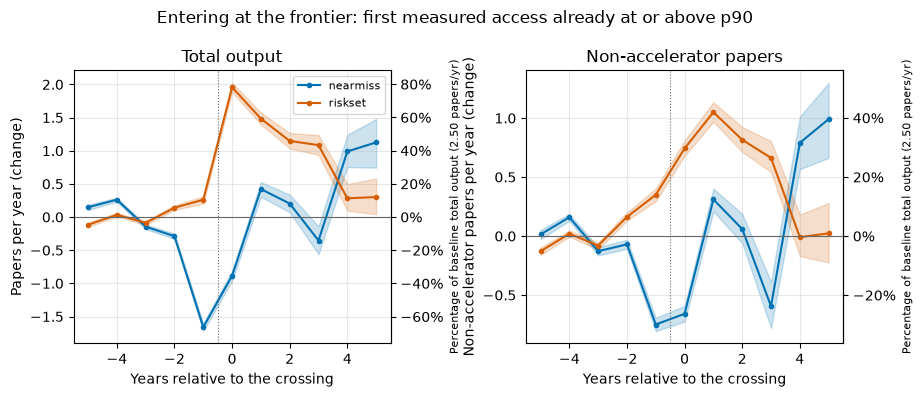

shape: (1, 3)
┌───────┬────────────────────┬────────────────────────┐
│ n     ┆ median_career_year ┆ median_baseline_papers │
│ ---   ┆ ---                ┆ ---                    │
│ u32   ┆ f64                ┆ f64                    │
╞═══════╪════════════════════╪════════════════════════╡
│ 27627 ┆ 9.0                ┆ 1.0                    │
└───────┴────────────────────┴────────────────────────┘


In [ ]:
res_entry = run_event_study(event_type='frontier_entry',
                            outcomes=('n_papers', 'n_nonaccel'))
plot_event_study(res_entry, outcomes=('n_papers', 'n_nonaccel'),
                 title='Entering at the frontier: first measured access already '
                       f'at or above {QLAB}')
print(ev.filter(pl.col('event_type') == 'frontier_entry').select(
    n=pl.len(), median_career_year=pl.col('career_year_at_event').median(),
    median_baseline_papers=pl.col('pre_papers_mean').median()))

### Pre-trend diagnostic — the headline check

If theta is already climbing before the crossing, the crossing is not the cause of
a change; it is a marker of one already underway. `authors.ipynb` found +20% of
baseline output at tau=-1 on its balanced sample, so this is the plot that decides
what can be claimed. It cannot rule out anticipation *without* a pre-trend (a
project that starts and buys hardware the same year) — that is what the placebo and
the coauthor split are for.

frontier_cross/nearmiss: 10,793 of 13,603 matched, 51,450 pairs, 9,813 controls, 4.8 per treated


frontier_entry/nearmiss: 16,935 of 27,627 matched, 73,551 pairs, 9,639 controls, 4.3 per treated


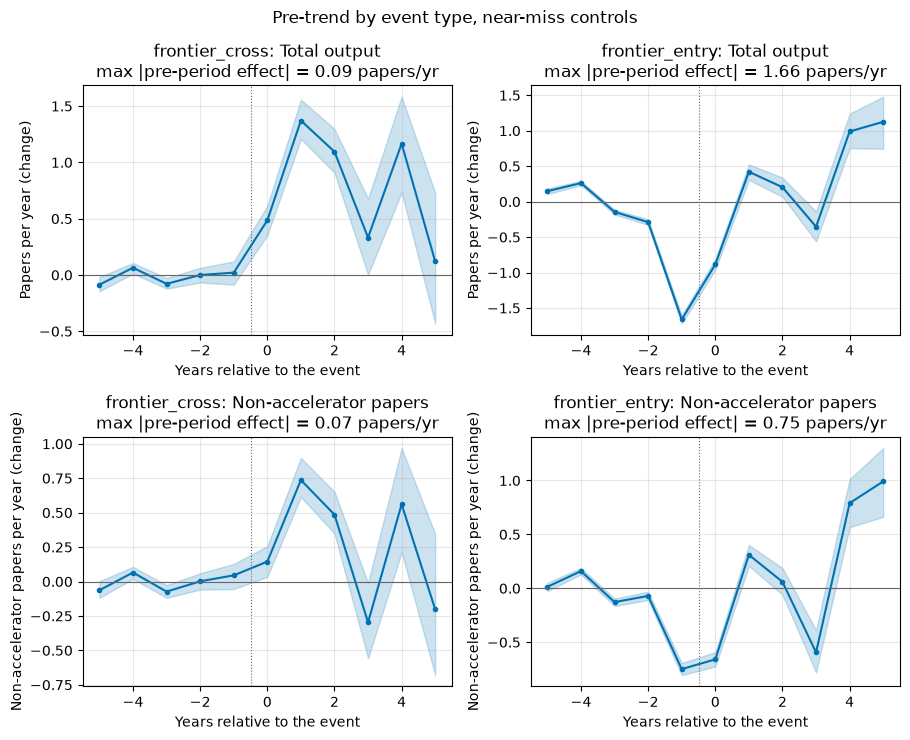

frontier_cross: max |pre-period theta| = 0.09 papers/yr = 2% of a 4.49 papers/yr baseline; theta at tau=-1 = 0.02
frontier_entry: max |pre-period theta| = 1.66 papers/yr = 66% of a 2.50 papers/yr baseline; theta at tau=-1 = -1.66


In [ ]:
res_by_event = {et: run_event_study(event_type=et,
                                   outcomes=('n_papers', 'n_nonaccel'),
                                   variants=('nearmiss',))
                for et in au.FRONTIER_EVENT_TYPES}
fig, axes = plt.subplots(2, len(au.FRONTIER_EVENT_TYPES),
                         figsize=(4.6 * len(au.FRONTIER_EVENT_TYPES), 7.5),
                         squeeze=False)
for col, et in enumerate(au.FRONTIER_EVENT_TYPES):
    for row, o in enumerate(('n_papers', 'n_nonaccel')):
        ax = axes[row][col]
        r = res_by_event[et][('nearmiss', o)]
        pre = r.filter(pl.col('tau') < 0)
        ax.fill_between(r['tau'], r['lo'], r['hi'], color=C_NM, alpha=0.20)
        ax.plot(r['tau'], r['theta'], marker='o', ms=3, color=C_NM)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the event', ylabel=ylab(o),
               title=f'{et}: {tlab(o)}\nmax |pre-period effect| = '
                     f'{pre["theta"].abs().max():.2f} papers/yr')
        ax.grid(alpha=0.3)
fig.suptitle('Pre-trend by event type, near-miss controls')
plt.tight_layout(); plt.show()

for et in au.FRONTIER_EVENT_TYPES:
    r = res_by_event[et][('nearmiss', 'n_papers')]
    pre = r.filter(pl.col('tau') < 0)
    b = res_by_event[et]['_baseline']
    print(f'{et}: max |pre-period theta| = {pre["theta"].abs().max():.2f} papers/yr '
          f'= {100 * pre["theta"].abs().max() / b:.0f}% of a {b:.2f} papers/yr '
          f'baseline; theta at tau=-1 = '
          f'{r.filter(pl.col("tau") == -1)["theta"][0]:.2f}')

### Placebo: pseudo-crossings on authors who never cross

The placebo pool is authors with at least one year of *measured access* who never
cross — not merely `ever_gpu`. An author whose accelerator papers never named a
spec'd model could never have crossed a capacity threshold, so including them would
dilute the placebo with units that were never at risk. Pseudo-event years are drawn
from the real event-year distribution, so treated and control units are the same
population differing only in a random date, and `risk_events=ev` keeps real
crossers out of the control pool.

167,335 placebo events on never-crossing authors with measured access (vs 13,603 real frontier_cross events)
baseline mean n_papers  placebo 3.70  | real 4.49   -- theta on log(1+n_papers) is only interpretable relative to this


frontier_cross/riskset: 166,076 of 167,335 matched, 821,891 pairs, 312,920 controls, 4.9 per treated


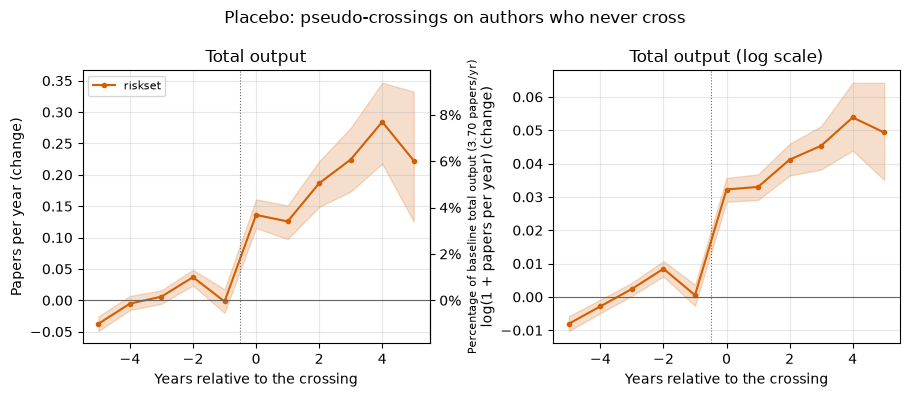

--- placebo n_papers ---
shape: (11, 5)
┌─────┬────────┬────────┬────────┬────────┐
│ tau ┆ theta  ┆ lo     ┆ hi     ┆ n      │
│ --- ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i64 ┆ f64    ┆ f64    ┆ f64    ┆ i64    │
╞═════╪════════╪════════╪════════╪════════╡
│ -5  ┆ -0.037 ┆ -0.049 ┆ -0.026 ┆ 166076 │
│ -4  ┆ -0.005 ┆ -0.016 ┆ 0.007  ┆ 166076 │
│ -3  ┆ 0.006  ┆ -0.006 ┆ 0.016  ┆ 166076 │
│ -2  ┆ 0.037  ┆ 0.024  ┆ 0.049  ┆ 166076 │
│ -1  ┆ -0.002 ┆ -0.02  ┆ 0.017  ┆ 166076 │
│ …   ┆ …      ┆ …      ┆ …      ┆ …      │
│ 1   ┆ 0.126  ┆ 0.097  ┆ 0.151  ┆ 146450 │
│ 2   ┆ 0.187  ┆ 0.149  ┆ 0.222  ┆ 105567 │
│ 3   ┆ 0.224  ┆ 0.173  ┆ 0.275  ┆ 69575  │
│ 4   ┆ 0.284  ┆ 0.218  ┆ 0.347  ┆ 35006  │
│ 5   ┆ 0.223  ┆ 0.125  ┆ 0.333  ┆ 16915  │
└─────┴────────┴────────┴────────┴────────┘
--- placebo log_papers ---
shape: (11, 5)
┌─────┬────────┬────────┬────────┬────────┐
│ tau ┆ theta  ┆ lo     ┆ hi     ┆ n      │
│ --- ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i64 ┆ f64    ┆ f64    ┆ f64    ┆ i64

frontier_cross/riskset: 11,152 of 13,603 matched, 54,783 pairs, 41,364 controls, 4.9 per treated


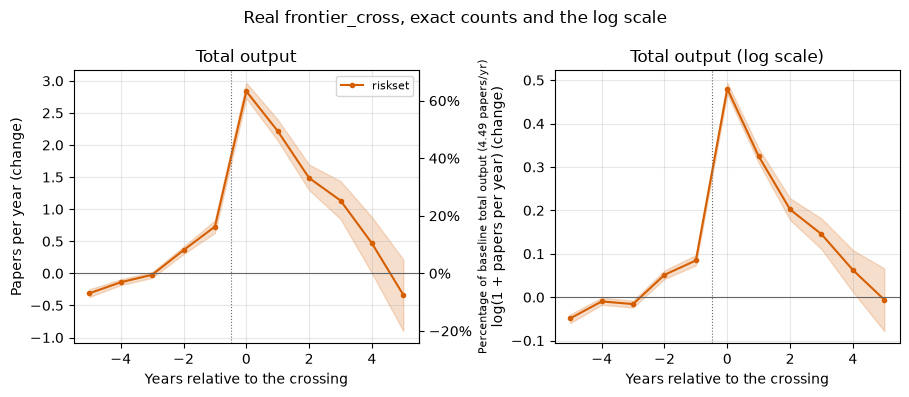

In [ ]:
placebo = au.placebo_jumps(gpu, ev, event_type=EVENT_TYPE, seed=au.SEED,
                           require=pl.col(ACCESS_COL).is_not_null())
print(f'{placebo.height:,} placebo events on never-crossing authors with measured '
      f'access (vs {fc.height:,} real {EVENT_TYPE} events)')
print(f'baseline mean n_papers  placebo {placebo["pre_papers_mean"].mean():.2f}  '
      f'| real {fc["pre_papers_mean"].mean():.2f}   '
      '-- theta on log(1+n_papers) is only interpretable relative to this')

OUT_PAIR = ('n_papers', 'log_papers')      # exact count, and the log scale
res_placebo = run_event_study(jump_table=placebo, outcomes=OUT_PAIR,
                              variants=('riskset',), risk_events=ev)
plot_event_study(res_placebo, outcomes=OUT_PAIR,
                 title='Placebo: pseudo-crossings on authors who never cross')
for o in OUT_PAIR:
    print(f'--- placebo {o} ---')
    print(res_placebo[('riskset', o)].sort('tau')
          .with_columns(pl.selectors.float().round(3)))

# the real estimate on the same two scales, so the comparison is like-for-like
res_raw = run_event_study(outcomes=OUT_PAIR, variants=('riskset',))
plot_event_study(res_raw, outcomes=OUT_PAIR,
                 title=f'Real {EVENT_TYPE}, exact counts and the log scale')

## Coauthor decomposition

The rival explanation is that the treatment is not the frontier hardware but a
well-equipped collaborator. `coauthor_sourced` is true when some coauthor of a
crossing paper already held at least half the crossing capacity in the prior year;
`coauthor_at_frontier` is the stricter frontier version — a coauthor who was
*already at or above the focal percentile* the year before. If the effect survives on crossings
where neither holds, and on small teams, then the collaborator is not the whole
story. If it does not, that is the finding.

Restricted to the events whose team columns transferred from the jumps table (the
same-year overlap), so the sample here is smaller than the headline.

frontier_cross/nearmiss: 4,925 of 6,184 matched, 23,242 pairs, 8,558 controls, 4.7 per treated


frontier_cross/nearmiss: 5,663 of 7,083 matched, 26,728 pairs, 8,900 controls, 4.7 per treated


frontier_cross/nearmiss: 3,382 of 4,409 matched, 16,379 pairs, 6,762 controls, 4.8 per treated


frontier_cross/nearmiss: 832 of 1,053 matched, 3,980 pairs, 3,007 controls, 4.8 per treated


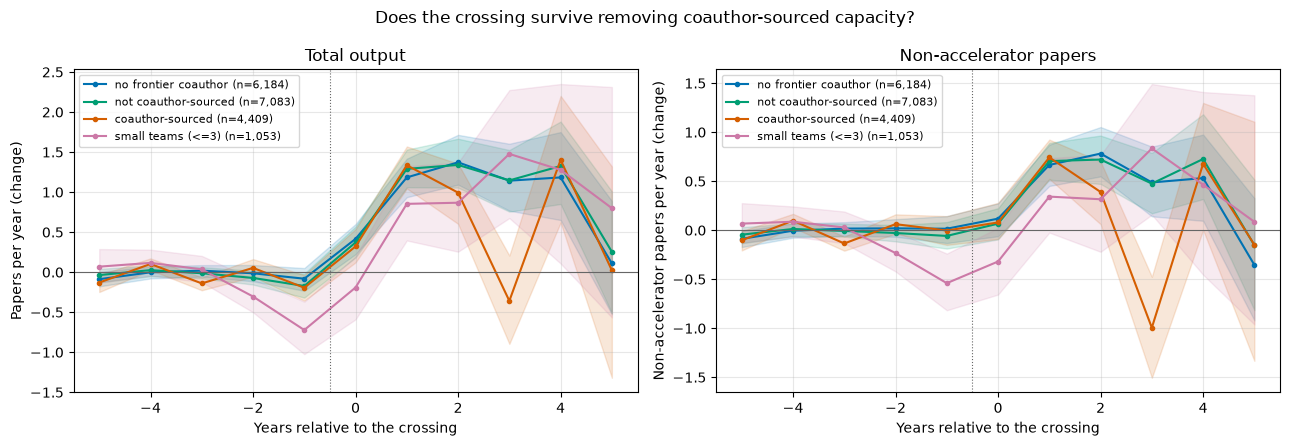

In [ ]:
sub = fc.filter(pl.col('min_team_size').is_not_null())
splits = {
    'no frontier coauthor': sub.filter(~pl.col('coauthor_at_frontier')),
    'not coauthor-sourced': sub.filter(~pl.col('coauthor_sourced')),
    'coauthor-sourced': sub.filter(pl.col('coauthor_sourced')),
    'small teams (<=3)': sub.filter(pl.col('min_team_size') <= 3),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (lab, jt), c in zip(splits.items(),
                        [C_MED, '#009E73', C_FRONT, '#CC79A7']):
    if jt.height < 50:
        print(f'skipping {lab}: only {jt.height} events')
        continue
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('nearmiss',))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('nearmiss', o)]
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'{lab} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Does the crossing survive removing coauthor-sourced capacity?')
plt.tight_layout(); plt.show()

## Citation outcomes

`i_3` needs three complete years, so the citation event study is restricted to
events at or before `au.CITATION_EVENT_CUTOFF`. Running it on later events would
report a mechanical decline in citations as an effect of frontier access. Since 93%
of crossings are 2020 or later, this is a small and early subsample — read it as
suggestive at best.

995 of 13,603 frontier_cross events at or before 2019


frontier_cross/nearmiss: 676 of 995 matched, 2,737 pairs, 526 controls, 4.0 per treated


frontier_cross/riskset: 788 of 995 matched, 3,638 pairs, 3,163 controls, 4.6 per treated


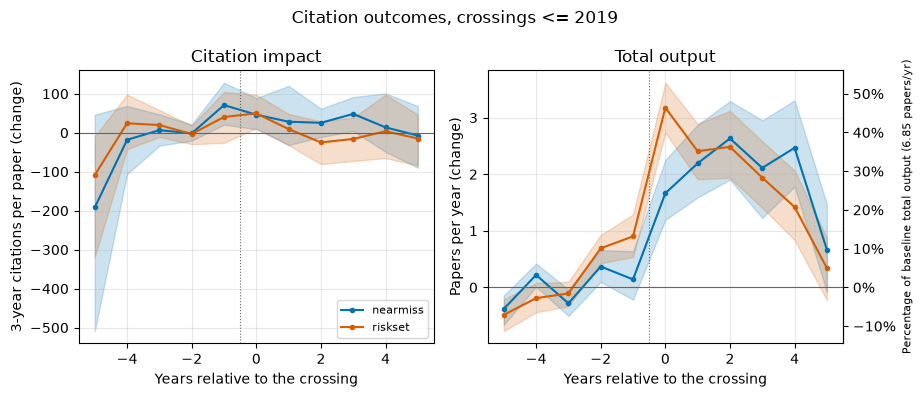

In [ ]:
cj = fc.filter(pl.col('event_year') <= au.CITATION_EVENT_CUTOFF)
print(f'{cj.height:,} of {fc.height:,} {EVENT_TYPE} events at or before '
      f'{au.CITATION_EVENT_CUTOFF}')
if cj.height < 100:
    print('too few events for a citation event study -- reported as unavailable')
else:
    res_cit = run_event_study(jump_table=cj, outcomes=('cit_i3_mean', 'n_papers'))
    plot_event_study(res_cit, outcomes=('cit_i3_mean', 'n_papers'),
                     title=f'Citation outcomes, crossings <= '
                           f'{au.CITATION_EVENT_CUTOFF}')

## Calendar time and composition

**What the percentile definition already fixes.** The event threshold is
re-estimated every year, so "reaching the frontier" means the same *relative*
thing in 2012 and 2025 and the 124x growth in absolute capacity is not part of the
event. That is the improvement over `ratio_jump`, whose detection probability rises
with model-naming specificity.

**What it does not fix.** Measurement still has to see a spec'd model at all, so
whether an author *appears* in the access distribution is trend-contaminated even
though their position within it is not. And composition across tau survives:
93% of crossings are 2020 or later, so tau=+1 is estimated on recent crossers while
tau=+5 rests on a different, earlier cohort. The balanced panel is the fix.

As in `authors.ipynb`, `match_controls` gives every control its treated author's
own event year, so calendar shocks common to a matched cell are differenced out
non-parametrically — stronger than an additive year dummy because it is fully
interacted with the matching cell. The two-way FE below writes the year effects
down explicitly as a cross-check.

A caveat balancing does **not** fix: `author_year_panel` densifies only from first
to last publication, so an author who stops publishing has *no* rows afterwards
rather than zero-output rows. Exit is missing data, not measured zero, which biases
late-tau estimates upward in every variant here.

860 of 13,603 frontier_cross events have a full [-5, +5] window
  dropped, window runs past the panel (2025): 11,590
  dropped, author stopped publishing first:        889   <- survivorship, not censoring


frontier_cross/nearmiss: 705 of 860 matched, 2,908 pairs, 1,092 controls, 4.1 per treated


frontier_cross/riskset: 807 of 860 matched, 3,750 pairs, 3,458 controls, 4.6 per treated


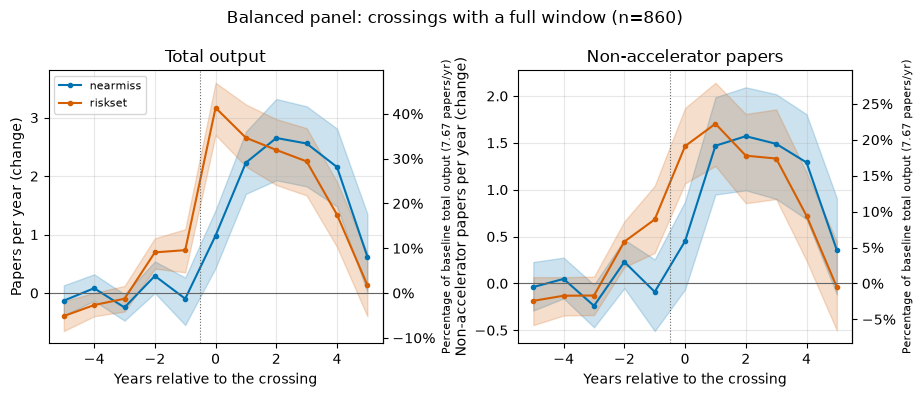

--- balanced n_papers (nearmiss controls) ---
shape: (11, 6)
┌─────┬───────┬───────┬───────┬───────────┬─────┐
│ tau ┆ theta ┆ lo    ┆ hi    ┆ theta_pct ┆ n   │
│ --- ┆ ---   ┆ ---   ┆ ---   ┆ ---       ┆ --- │
│ i64 ┆ f64   ┆ f64   ┆ f64   ┆ f64       ┆ i64 │
╞═════╪═══════╪═══════╪═══════╪═══════════╪═════╡
│ -5  ┆ -0.13 ┆ -0.39 ┆ 0.13  ┆ -1.69     ┆ 705 │
│ -4  ┆ 0.08  ┆ -0.13 ┆ 0.32  ┆ 1.08      ┆ 705 │
│ -3  ┆ -0.25 ┆ -0.47 ┆ -0.02 ┆ -3.21     ┆ 705 │
│ -2  ┆ 0.29  ┆ 0.0   ┆ 0.54  ┆ 3.83      ┆ 705 │
│ -1  ┆ -0.1  ┆ -0.55 ┆ 0.27  ┆ -1.27     ┆ 705 │
│ …   ┆ …     ┆ …     ┆ …     ┆ …         ┆ …   │
│ 1   ┆ 2.23  ┆ 1.7   ┆ 2.76  ┆ 29.11     ┆ 705 │
│ 2   ┆ 2.65  ┆ 1.93  ┆ 3.32  ┆ 34.6      ┆ 702 │
│ 3   ┆ 2.56  ┆ 1.82  ┆ 3.19  ┆ 33.38     ┆ 701 │
│ 4   ┆ 2.16  ┆ 1.48  ┆ 2.81  ┆ 28.12     ┆ 680 │
│ 5   ┆ 0.62  ┆ 0.01  ┆ 1.35  ┆ 8.13      ┆ 635 │
└─────┴───────┴───────┴───────┴───────────┴─────┘
--- balanced n_papers (riskset controls) ---
shape: (11, 6)
┌─────┬───────┬───────┬──────

In [ ]:
# Balanced panel: the same authors at every tau
PANEL_HI = int(panel['year'].max())
e32 = pl.col('event_year').cast(pl.Int32)
y1 = panel.group_by('authorid').agg(pl.first('y1'))
n_censored = fc.filter(e32 + au.TAU_MAX > PANEL_HI).height
n_exit = (fc.filter(e32 + au.TAU_MAX <= PANEL_HI).join(y1, on='authorid', how='inner')
          .filter(pl.col('y1') < e32 + au.TAU_MAX).height)
bal = au.balanced_jumps(pos, fc)
print(f'{bal.height:,} of {fc.height:,} {EVENT_TYPE} events have a full '
      f'[{au.TAU_MIN}, +{au.TAU_MAX}] window')
print(f'  dropped, window runs past the panel ({PANEL_HI}): {n_censored:,}')
print(f'  dropped, author stopped publishing first:        {n_exit:,}'
      f'   <- survivorship, not censoring')

res_bal = run_event_study(jump_table=bal, outcomes=('n_papers', 'n_nonaccel'))
plot_event_study(res_bal, outcomes=('n_papers', 'n_nonaccel'),
                 title=f'Balanced panel: crossings with a full window '
                       f'(n={bal.height:,})')
BAL_BASE = res_bal['_baseline']
for o in ('n_papers', 'n_nonaccel'):
    for arm in CONTROL_ARMS:
        if (arm, o) not in res_bal:
            continue
        print(f'--- balanced {o} ({arm} controls) ---')
        print(au.as_share_of_baseline(res_bal[(arm, o)].sort('tau'), BAL_BASE)
              .select('tau', 'theta', 'lo', 'hi', 'theta_pct', 'n')
              .with_columns(pl.selectors.float().round(2)))

frontier_cross/nearmiss: 676 of 995 matched, 2,737 pairs, 526 controls, 4.0 per treated


frontier_cross/nearmiss: 2,079 of 2,794 matched, 9,843 pairs, 2,234 controls, 4.7 per treated


frontier_cross/nearmiss: 4,072 of 5,436 matched, 19,430 pairs, 3,549 controls, 4.8 per treated


frontier_cross/nearmiss: 3,975 of 4,378 matched, 19,363 pairs, 4,480 controls, 4.9 per treated


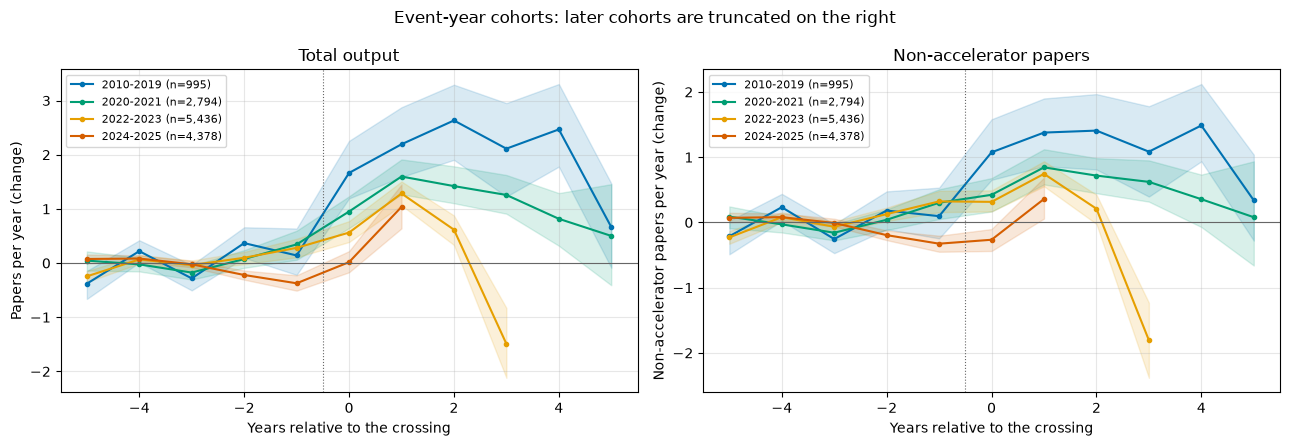

In [ ]:
# Event-year cohorts: is the tau profile stable across calendar eras?
COHORTS = [(2010, 2019), (2020, 2021), (2022, 2023), (2024, 2025)]
C_COHORT = ['#0072B2', '#009E73', '#E69F00', '#D55E00']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (a, b), c in zip(COHORTS, C_COHORT):
    jt = fc.filter(pl.col('event_year').is_between(a, b))
    if jt.height < 100:
        print(f'skipping {a}-{b}: only {jt.height} events')
        continue
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('nearmiss',))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('nearmiss', o)].sort('tau')
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'{a}-{b} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Event-year cohorts: later cohorts are truncated on the right')
plt.tight_layout(); plt.show()

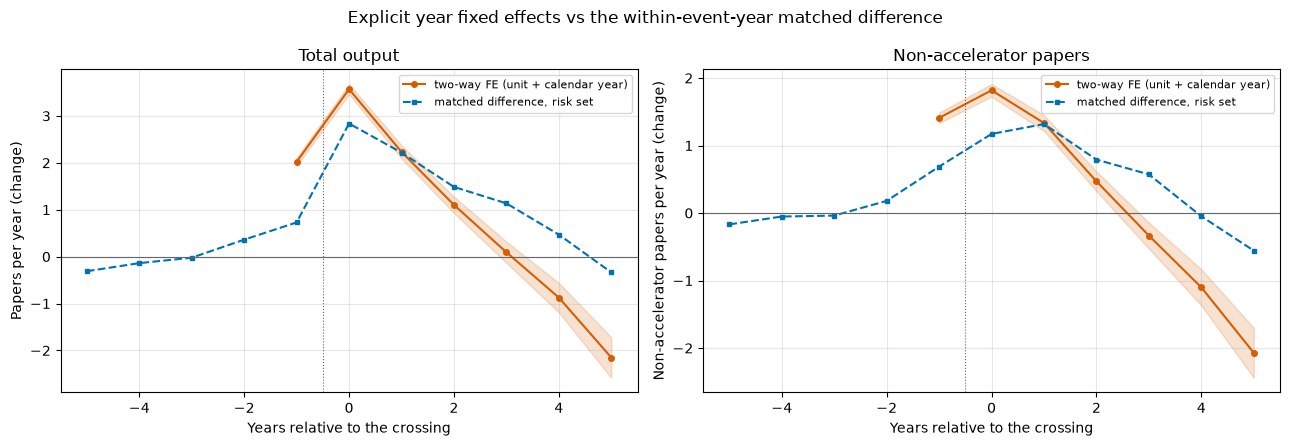

--- n_papers: two-way FE vs matched difference ---
shape: (7, 6)
┌─────┬────────┬───────┬────────┬───────┬─────────┐
│ tau ┆ beta   ┆ se    ┆ theta  ┆ gap   ┆ n_units │
│ --- ┆ ---    ┆ ---   ┆ ---    ┆ ---   ┆ ---     │
│ i64 ┆ f64    ┆ f64   ┆ f64    ┆ f64   ┆ i64     │
╞═════╪════════╪═══════╪════════╪═══════╪═════════╡
│ -1  ┆ 2.02   ┆ 0.045 ┆ 0.728  ┆ 1.292 ┆ 60976   │
│ 0   ┆ 3.57   ┆ 0.056 ┆ 2.837  ┆ 0.733 ┆ 60976   │
│ 1   ┆ 2.233  ┆ 0.072 ┆ 2.218  ┆ 0.015 ┆ 60976   │
│ 2   ┆ 1.103  ┆ 0.089 ┆ 1.486  ┆ 0.383 ┆ 60976   │
│ 3   ┆ 0.093  ┆ 0.115 ┆ 1.135  ┆ 1.042 ┆ 60976   │
│ 4   ┆ -0.873 ┆ 0.161 ┆ 0.469  ┆ 1.343 ┆ 60976   │
│ 5   ┆ -2.151 ┆ 0.221 ┆ -0.336 ┆ 1.815 ┆ 60976   │
└─────┴────────┴───────┴────────┴───────┴─────────┘
  max |beta - theta| = 1.815
--- n_nonaccel: two-way FE vs matched difference ---
shape: (7, 6)
┌─────┬────────┬───────┬────────┬───────┬─────────┐
│ tau ┆ beta   ┆ se    ┆ theta  ┆ gap   ┆ n_units │
│ --- ┆ ---    ┆ ---   ┆ ---    ┆ ---   ┆ ---     │
│ i64 ┆

n_papers: max |beta - theta| = 1.82 on the full sample, 0.69 on the balanced one


In [ ]:
# Two-way fixed effects: unit AND calendar-year dummies, written down explicitly.
# Reference is the whole baseline window, so beta is directly comparable to theta.
ctrl_fe = au.match_controls(pos, fc, variant='riskset', seed=au.SEED,
                            risk_events=ev, extra_stratum='frontier_gap')
fe = {o: au.twoway_fe(pos, fc, ctrl_fe, o) for o in ('n_papers', 'n_nonaccel')}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    f = fe[o].sort('tau')
    t = res_main[('riskset', o)].sort('tau')
    ax.fill_between(f['tau'], f['lo'], f['hi'], color=C_FRONT, alpha=0.18)
    ax.plot(f['tau'], f['beta'], marker='o', ms=4, color=C_FRONT,
            label='two-way FE (unit + calendar year)')
    ax.plot(t['tau'], t['theta'], marker='s', ms=3, ls='--', color=C_MED,
            label='matched difference, risk set')
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Explicit year fixed effects vs the within-event-year matched difference')
plt.tight_layout(); plt.show()

for o in ('n_papers', 'n_nonaccel'):
    j = (fe[o].join(res_main[('riskset', o)].select('tau', 'theta'), on='tau',
                    how='inner').sort('tau')
         .with_columns(gap=(pl.col('beta') - pl.col('theta')).abs()))
    print(f'--- {o}: two-way FE vs matched difference ---')
    print(j.select('tau', 'beta', 'se', 'theta', 'gap', 'n_units')
           .with_columns(pl.selectors.float().round(3)))
    print(f'  max |beta - theta| = {j["gap"].max():.3f}')

# Two-way FE is fragile under concentrated event timing, and 93% of these events
# are 2020+, which makes calendar year and event time nearly collinear. On the
# balanced sample the timing is spread out; if beta and theta agree there and only
# diverge on the full sample, the divergence is the FE estimator's problem.
fe_bal = au.twoway_fe(pos, bal,
                      au.match_controls(pos, bal, seed=au.SEED, risk_events=ev,
                                        extra_stratum='frontier_gap'),
                      'n_papers')
gap_full = (fe['n_papers'].join(res_main[('riskset', 'n_papers')].select('tau', 'theta'),
                                on='tau')
            .select((pl.col('beta') - pl.col('theta')).abs().max()).item())
gap_bal = (fe_bal.join(res_bal[('riskset', 'n_papers')].select('tau', 'theta'), on='tau')
           .select((pl.col('beta') - pl.col('theta')).abs().max()).item())
print(f'n_papers: max |beta - theta| = {gap_full:.2f} on the full sample, '
      f'{gap_bal:.2f} on the balanced one')

## Robustness

1. **Threshold** — a sweep centred on `FRONTIER_Q` (p75 / p90 / p95 at the
   default), since a lower bar is a larger, milder event. The near-miss band moves
   with each focal value, so every arm keeps a like-for-like control pool.
2. **Access axis** — VRAM instead of FP32.
3. **Stock instead of flow** — crossing on the running-max stock, so a one-off
   year at the frontier still counts as having reached it.
4. **Count policy** floor1 vs explicit.

frontier_cross/nearmiss: 17,758 of 22,558 matched, 84,388 pairs, 7,924 controls, 4.8 per treated


frontier_cross/nearmiss: 10,793 of 13,603 matched, 51,450 pairs, 9,813 controls, 4.8 per treated


frontier_cross/nearmiss: 6,472 of 8,036 matched, 31,093 pairs, 10,516 controls, 4.8 per treated


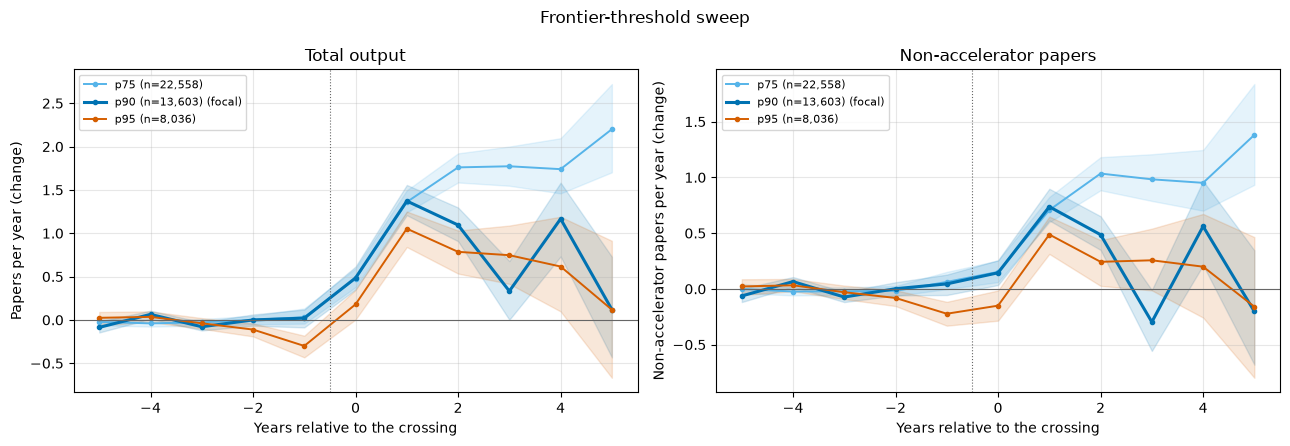

In [ ]:
# Threshold sweep, centred on whatever FRONTIER_Q is set to. Thresholds, events and
# the near-miss pool all move together: a p75 crossing needs a p60-p75 near-miss
# band, not the p75-p90 one, or the "controls" would include authors above the bar.
SWEEP_Q = sorted({round(FRONTIER_Q + d, 2) for d in (-0.15, 0.0, 0.05)}
                 & {q / 100 for q in range(50, 100)})
# every focal AND its near-miss edge has to exist in one threshold table
SWEEP_ALL = tuple(sorted({q for f in SWEEP_Q
                          for q in (f, round(f - NEAR_MISS_BAND, 2))
                          if 0 < q < 1}))
thr_sweep = au.frontier_thresholds(gpu, ACCESS_COL, quantiles=SWEEP_ALL)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for q, c in zip(SWEEP_Q, (C_P90, C_MED, C_FRONT, '#009E73')):
    e_q = au.find_frontier_events(gpu, quantile=q, col=ACCESS_COL,
                                  thresholds=thr_sweep)
    jt = e_q.filter(pl.col('event_type') == EVENT_TYPE)
    nm_q = au.near_miss_candidates(gpu, thr_sweep, col=ACCESS_COL, quantile=q,
                                   lower_quantile=round(q - NEAR_MISS_BAND, 2))
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('nearmiss',), candidates=nm_q, risk_events=e_q)
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('nearmiss', o)]
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                lw=2.2 if q == FRONTIER_Q else 1.4,
                label=f'{qlab(q)} (n={jt.height:,})'
                      + (' (focal)' if q == FRONTIER_Q else ''))
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Frontier-threshold sweep')
plt.tight_layout(); plt.show()

VRAM: 13,461 crossings vs 13,603 on the FP32 flow; author overlap 0.59 Jaccard


frontier_cross/nearmiss: 10,835 of 13,461 matched, 52,223 pairs, 10,770 controls, 4.8 per treated


FP32 stock (running max): 16,288 crossings vs 13,603 on the FP32 flow; author overlap 0.78 Jaccard


frontier_cross/nearmiss: 13,500 of 16,288 matched, 66,333 pairs, 19,672 controls, 4.9 per treated


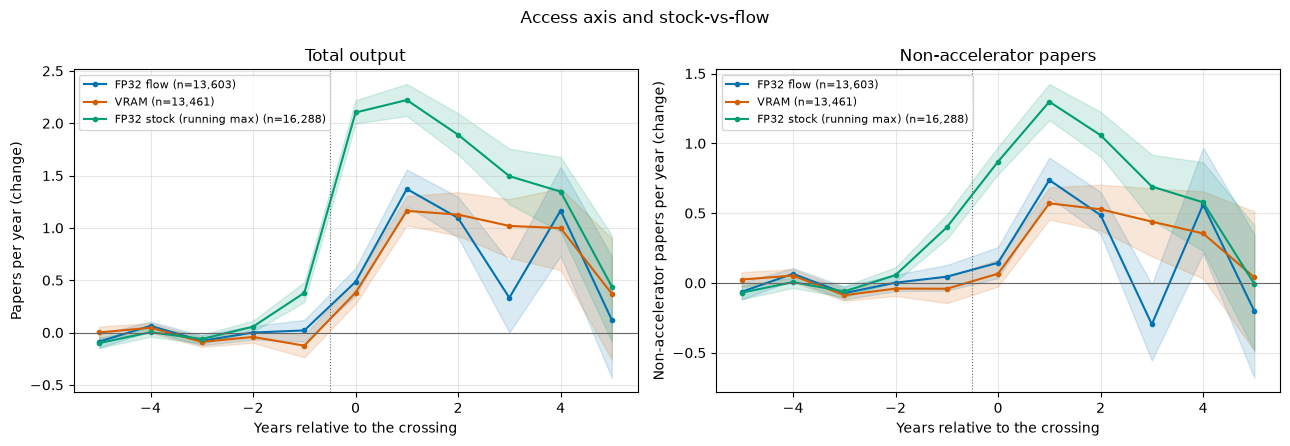

In [ ]:
# VRAM instead of FP32, and the stock instead of the flow.
ALTS = (('VRAM', 'access_vram_max', gpu, C_FRONT),
        ('FP32 stock (running max)', 'access_fp32_stock', gpu, '#009E73'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    d = res_main[('nearmiss', o)]
    ax.fill_between(d['tau'], d['lo'], d['hi'], color=C_MED, alpha=0.15)
    ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=C_MED,
            label=f'FP32 flow (n={fc.height:,})')
for lab, col, src, c in ALTS:
    t_alt = au.frontier_thresholds(src, col, quantiles=QUANTILES)
    e_alt = au.find_frontier_events(src, quantile=FRONTIER_Q, col=col,
                                    thresholds=t_alt)
    jt = e_alt.filter(pl.col('event_type') == EVENT_TYPE)
    nm_alt = au.near_miss_candidates(src, t_alt, col=col, quantile=FRONTIER_Q,
                                     lower_quantile=NEAR_MISS_Q)
    print(f'{lab}: {jt.height:,} crossings vs {fc.height:,} on the FP32 flow; '
          f'author overlap '
          f'{len(set(jt["authorid"]) & set(fc["authorid"])) / len(set(jt["authorid"]) | set(fc["authorid"])):.2f} Jaccard')
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('nearmiss',), candidates=nm_alt, risk_events=e_alt)
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('nearmiss', o)]
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'{lab} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Access axis and stock-vs-flow')
plt.tight_layout(); plt.show()

crosser-set Jaccard floor1 vs explicit: 0.819 (13,603 vs 11,589)
same event year for 98.1% of the 11,341 authors in both


frontier_cross/nearmiss: 9,243 of 11,589 matched, 44,278 pairs, 8,960 controls, 4.8 per treated


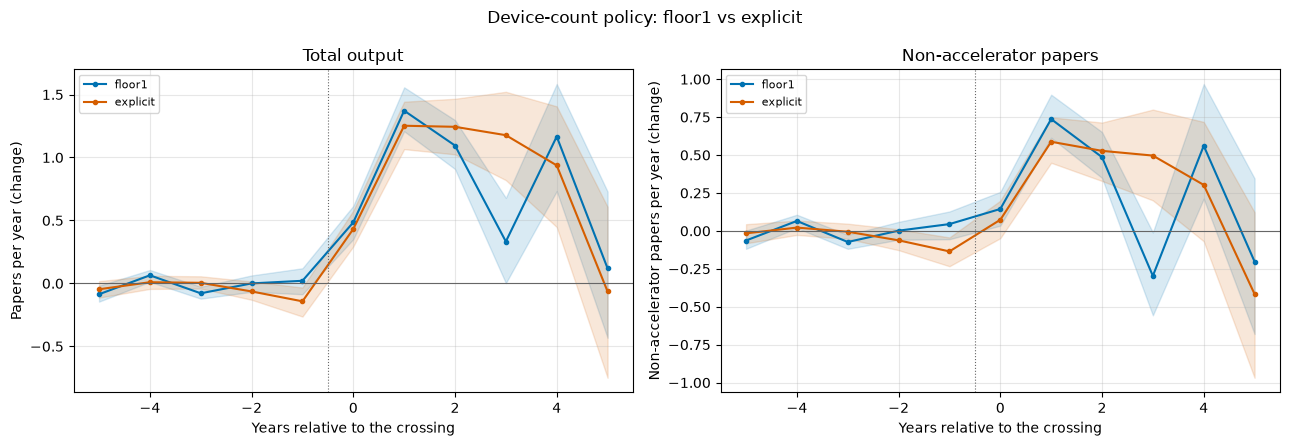

In [ ]:
# floor1 vs explicit device counts: do the two policies pick the same crossers?
try:
    alt_panel = au.add_outcomes(load('author_year', 'explicit').filter(
        pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
except Exception as e:                       # the explicit variant may not be built
    print(f'explicit panel unavailable: {e}')
    alt_panel = None

if alt_panel is not None:
    alt_gpu = alt_panel.filter(pl.col('control_sample') == 'gpu_ever')
    alt_thr = au.frontier_thresholds(alt_gpu, ACCESS_COL, quantiles=QUANTILES)
    alt_pos = au.frontier_position(alt_panel, alt_thr, ACCESS_COL, FRONTIER_Q)
    alt_ev = au.find_frontier_events(alt_gpu, quantile=FRONTIER_Q, col=ACCESS_COL,
                                     thresholds=alt_thr)
    alt_fc = alt_ev.filter(pl.col('event_type') == EVENT_TYPE)
    alt_nm = au.near_miss_candidates(alt_gpu, alt_thr, col=ACCESS_COL,
                                     quantile=FRONTIER_Q, lower_quantile=NEAR_MISS_Q)
    a, b = set(fc['authorid']), set(alt_fc['authorid'])
    print(f'crosser-set Jaccard floor1 vs explicit: {len(a & b) / len(a | b):.3f} '
          f'({len(a):,} vs {len(b):,})')
    same = (fc.select('authorid', 'event_year')
            .join(alt_fc.select('authorid', alt_year='event_year'),
                  on='authorid', how='inner'))
    print(f'same event year for '
          f'{100 * (same["event_year"] == same["alt_year"]).mean():.1f}% of the '
          f'{same.height:,} authors in both')
    r_alt = run_event_study(jump_table=alt_fc, panel_df=alt_pos,
                            outcomes=('n_papers', 'n_nonaccel'),
                            variants=('nearmiss',), candidates=alt_nm,
                            risk_events=alt_ev)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        for lab, r, c in (('floor1', res_main, C_MED), ('explicit', r_alt, C_FRONT)):
            d = r[('nearmiss', o)]
            ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
            ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c, label=lab)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the crossing', ylabel=ylab(o), title=tlab(o))
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle('Device-count policy: floor1 vs explicit')
    plt.tight_layout(); plt.show()

## Standing caveats for the paper

Everything in `authors.ipynb`'s caveat list applies here unchanged:

- **Not causal.** Access is chosen. The design controls for *timing* among
  accelerator-using peers; it cannot control for the project that motivated the
  purchase. Anticipation inflates theta and leaves no pre-trend signature.
- **tau=0 is mechanical.** The crossing is itself a paper.
- **Author-id error is not symmetric.** Splits truncate careers and attenuate
  post-event effects; merges inflate output and can fabricate events.
- **Access is what was *reported*, nameplate peak, not utilized FLOPs** — the same
  caveat as every §5 capacity figure.
- **Exit is missing data, not measured zero.** The panel densifies only between an
  author's first and last publication, which biases late-tau estimates upward.
- **Coauthor access is exact for accelerator papers only** — a coauthor whose
  capacity never appeared in a full-text accelerator paper reads as no access.

Plus two that are specific to this notebook:

- **81% of crossings are also `ratio_jump` events in the same year.** This is
  largely the `authors.ipynb` result seen through a frontier-relative lens, not an
  independent confirmation of it. The overlap cell quantifies it and the two theta
  profiles are overlaid; report them together or not at all.
- **The focal percentile is a within-measured-population frontier.** It is computed among panel
  authors with *measured* access — an author using an unnamed GPU, or a named model
  with no registry spec, is absent from the reference distribution entirely. So
  "the 90th percentile of author compute" means the 90th percentile of the compute
  we can *see*, which is a selected and (in the earlier years) small population;
  years with fewer than `au.MIN_YEAR_N` such authors get no threshold at all and
  therefore contribute no events.
- **Team and coauthor columns cover only the same-year overlap** with the stage-4b
  jumps table, so the coauthor decomposition runs on a subsample of the crossings
  and its levels are not comparable to the headline.